# Explainability: SHAP Values
In this notebook, we use SHAP (SHapley Additive exPlanations) to interpret our machine learning model and understand the key drivers of customer churn.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib

# Initialize JS visualization for SHAP
shap.initjs()

## 1. Load Data and Trained Model

In [2]:
# Load the cleaned dataset
df = pd.read_csv('../data/processed/churn_clean.csv')

# Drop customerID for consistency with the model
if 'customerID' in df.columns:
    df = df.drop('customerID', axis=1)

X = df.drop('Churn', axis=1)
y = df['Churn'].map({'Yes': 1, 'No': 0})

# Load the trained model pipeline (Logistic Regression or XGBoost)
# Adjust the path to load the correct model from the previous step
model_pipeline = joblib.load('../models/churn_model.joblib')

print("Model and Data loaded successfully.")

Model and Data loaded successfully.


## 2. Preprocess the Data for SHAP

In [3]:
# Get the preprocessor and the actual classifier from the pipeline
preprocessor = model_pipeline.named_steps['preprocessor']
classifier = model_pipeline.named_steps['classifier']

# Transform the input features
X_transformed = preprocessor.transform(X)

# Get feature names after transformation
numeric_features = preprocessor.transformers_[0][2]
categorical_features = preprocessor.transformers_[1][1].get_feature_names_out(preprocessor.transformers_[1][2])
feature_names = np.concatenate([numeric_features, categorical_features])

# Create a DataFrame with the transformed features
X_transformed_df = pd.DataFrame(X_transformed, columns=feature_names)
X_transformed_df.head()

,tenure,MonthlyCharges,TotalCharges,gender_Male,SeniorCitizen_Yes,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,...,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,-1.281624,-1.164077,-0.995824,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1,0.061666,-0.264803,-0.179831,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-1.240918,-0.367672,-0.961467,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,0.509429,-0.750942,-0.201222,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,-1.240918,0.191470,-0.942379,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


## 3. Compute SHAP Values

In [4]:
# Compute SHAP values
# We use the LinearExplainer for Logistic Regression, or TreeExplainer for Random Forest/XGBoost
import warnings
warnings.filterwarnings('ignore')

# Check if the classifier is a Linear Model or Tree-based Model
if hasattr(classifier, 'coef_'):
    explainer = shap.LinearExplainer(classifier, X_transformed_df)
else:
    explainer = shap.TreeExplainer(classifier)

shap_values = explainer.shap_values(X_transformed_df)

print("SHAP values computed.")

SHAP values computed.


## 4. SHAP Summary Plot
This plot shows the most important features driving churn. Features pushed to the right increase the likelihood of churn, while features pushed to the left decrease it.

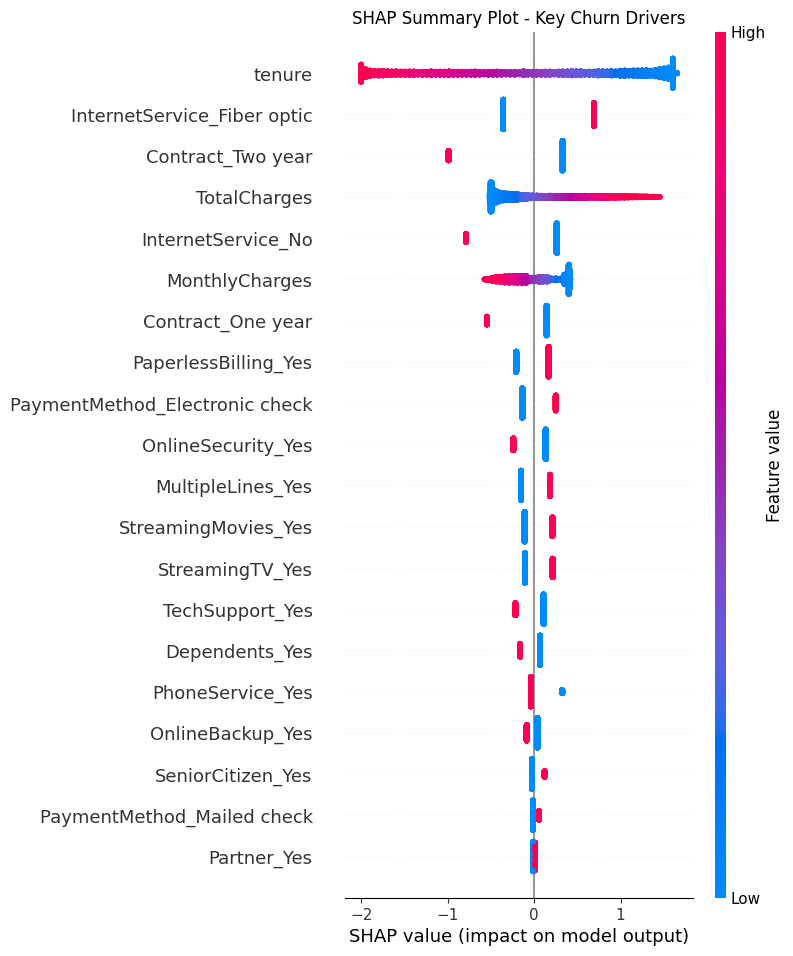

In [5]:
# Summary plot of all features
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_transformed_df, show=False)
plt.title('SHAP Summary Plot - Key Churn Drivers')
plt.show()

## 5. Per-Customer Explanation Plot
We can break down why a specific individual was predicted to churn or not.

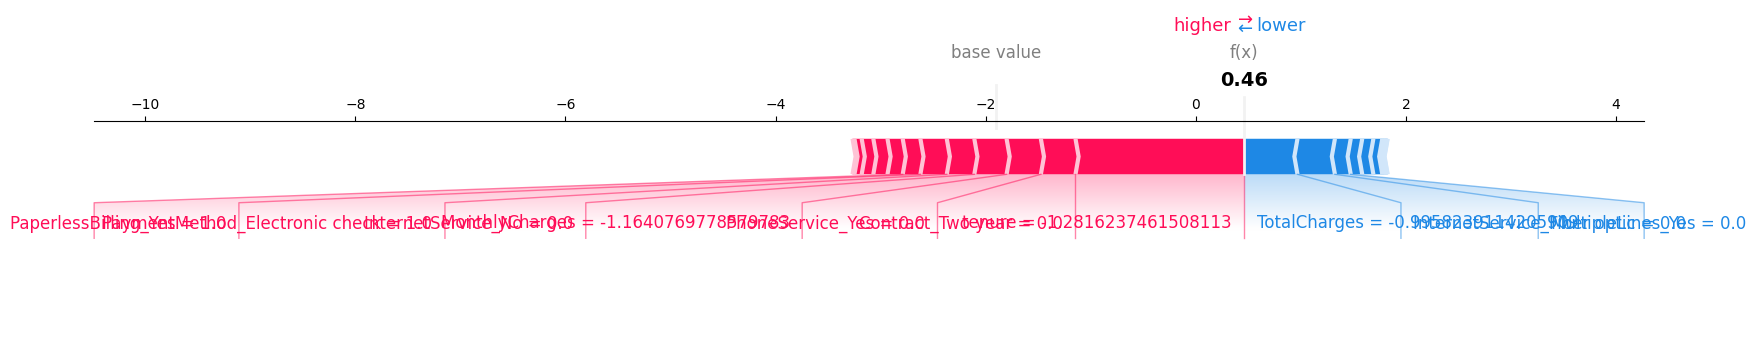

In [6]:
# Explanation for a single customer (e.g., customer at index 0)
customer_idx = 0
shap.force_plot(explainer.expected_value, shap_values[customer_idx,:], X_transformed_df.iloc[customer_idx,:], matplotlib=True)